Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
SKILL 9: INFERENCE BASELINE MEASUREMENT

SYSTEM INFORMATION
---------------------------------------------
PyTorch Version: 2.14.1+cpu
Device: cpu
GPU not available. Running on CPU.

LOADING YOLO MODEL
---------------------------------------------
Model loaded successfully.
Model: YOLO11n
Dataset: COCO8
Image Size: 640 x 640

RUNNING MODEL VALIDATION
---------------------------------------------
Ultralytics 8.4.220 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

WARNING ⚠️ Dataset 'coco8.yaml' images not found, missing path '/content/datasets/coco8/images/val'
Unzipping /content/datasets/coco8.zip to 

,Metric,Measured Value
0,Precision (accuracy-like),57.050
1,Recall,85.000
2,mAP@50,86.060
3,mAP@50:95,63.660
4,Average Latency (ms/image),164.448
5,Minimum Latency (ms/image),155.941
6,Maximum Latency (ms/image),181.754
7,CPU Usage (%),54.300
8,RAM Usage (%),15.000
9,GPU Allocated Memory (MB),0.000



GENERATING PERFORMANCE GRAPHS


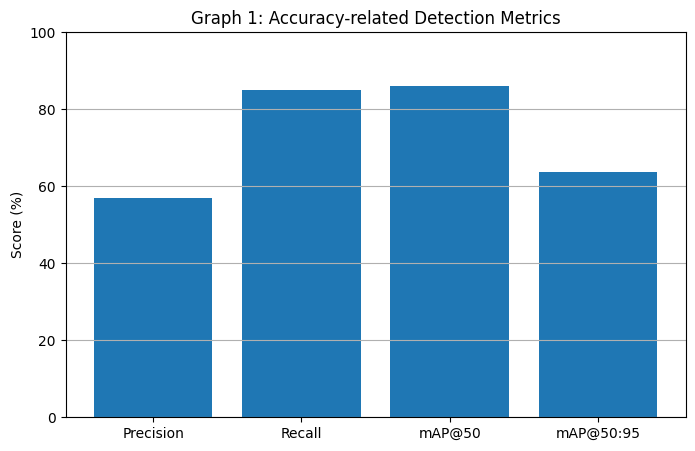

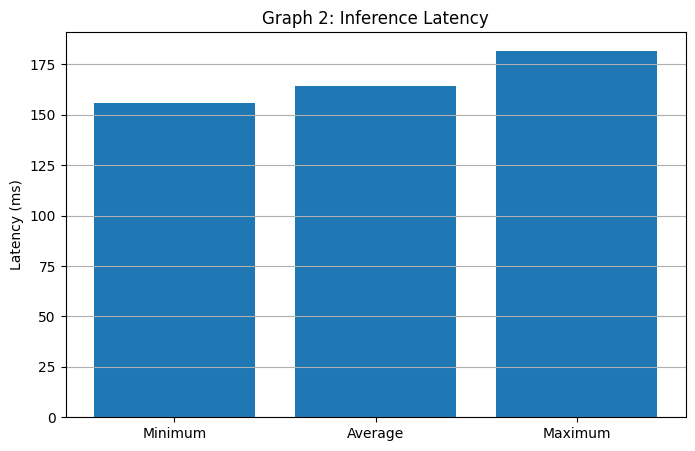

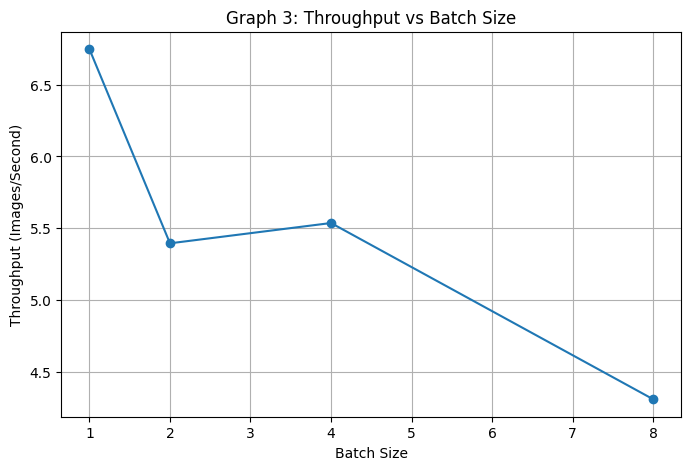

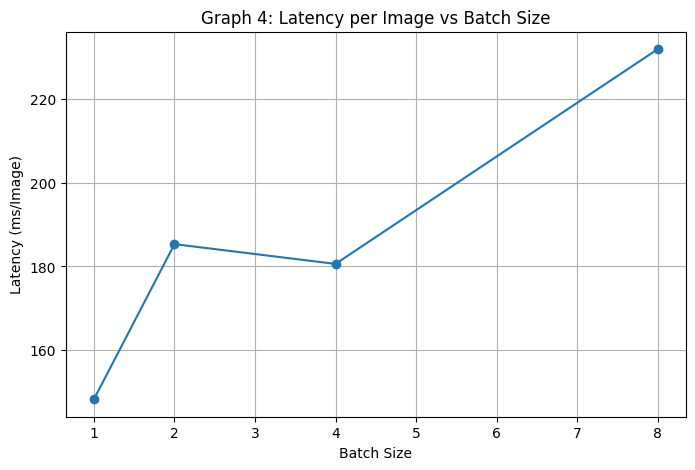

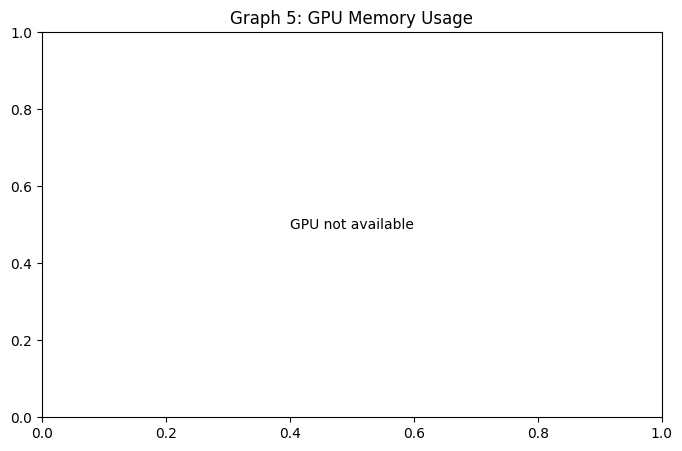

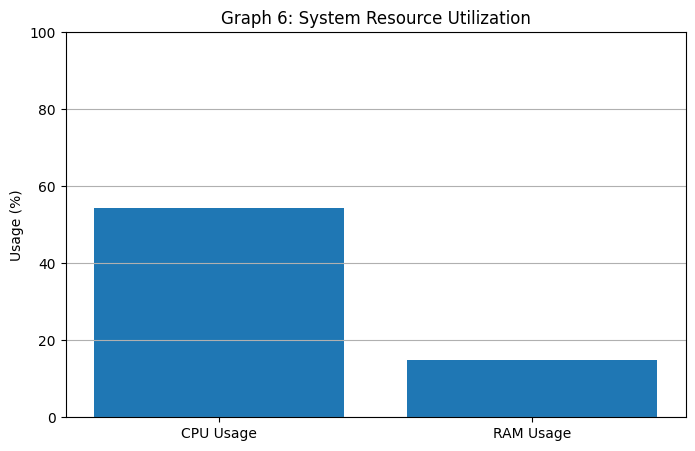


Results saved to:
skill9_inference_baseline_results.csv


SKILL 9 EXPERIMENT COMPLETED
Precision:       57.05%
Recall:          85.00%
mAP@50:          86.06%
mAP@50:95:       63.66%
Latency:         164.448 ms/image
Best Throughput: 6.75 images/sec

All six performance graphs generated.
Experiment finished successfully.


In [ ]:

# ============================================================
# SKILL 9: INFERENCE BASELINE MEASUREMENT
# Accuracy, mAP, Latency, Throughput and GPU Memory
# Complete Google Colab Program
# ============================================================

# STEP 1: INSTALL LIBRARIES

!pip -q install ultralytics psutil

import os
import glob
import time
import math
import torch
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset
from IPython.display import display

print("=" * 65)
print("SKILL 9: INFERENCE BASELINE MEASUREMENT")
print("=" * 65)


# STEP 2: CHECK SYSTEM AND GPU

device = 0 if torch.cuda.is_available() else "cpu"
gpu_available = torch.cuda.is_available()

print("\nSYSTEM INFORMATION")
print("-" * 45)
print("PyTorch Version:", torch.__version__)
print("Device:", device)

if gpu_available:
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("GPU not available. Running on CPU.")


# STEP 3: LOAD PRETRAINED YOLO MODEL

print("\nLOADING YOLO MODEL")
print("-" * 45)

model = YOLO("yolo11n.pt")

print("Model loaded successfully.")
print("Model: YOLO11n")
print("Dataset: COCO8")
print("Image Size: 640 x 640")


# STEP 4: VALIDATE MODEL AND CALCULATE ACCURACY / MAP

print("\nRUNNING MODEL VALIDATION")
print("-" * 45)

validation_results = model.val(
    data="coco8.yaml",
    split="val",
    imgsz=640,
    batch=4,
    device=device,
    plots=False,
    verbose=False
)

# Object detection does not have one universal
# classification-style accuracy value.
# We report precision as an accuracy-like measure.

precision = float(validation_results.box.mp)
recall = float(validation_results.box.mr)
map50 = float(validation_results.box.map50)
map5095 = float(validation_results.box.map)

print("\nVALIDATION RESULTS")
print("-" * 45)
print(f"Precision (accuracy-like measure): {precision * 100:.2f}%")
print(f"Recall:                            {recall * 100:.2f}%")
print(f"mAP@50:                            {map50 * 100:.2f}%")
print(f"mAP@50:95:                         {map5095 * 100:.2f}%")


# STEP 5: FIND VALIDATION IMAGES

print("\nLOADING VALIDATION IMAGES")
print("-" * 45)

data_info = check_det_dataset("coco8.yaml")
val_directory = data_info["val"]

image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.bmp"]

image_paths = []

for extension in image_extensions:
    image_paths.extend(
        glob.glob(os.path.join(val_directory, extension))
    )

image_paths = sorted(image_paths)

if len(image_paths) == 0:
    raise RuntimeError(
        "No validation images found. Check the COCO8 dataset download."
    )

print("Validation image directory:", val_directory)
print("Number of validation images:", len(image_paths))


# STEP 6: DEFINE GPU SYNCHRONIZATION

def synchronize_gpu():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


# STEP 7: MEASURE INFERENCE LATENCY

print("\nMEASURING INFERENCE LATENCY")
print("-" * 45)

# Warm-up
for _ in range(3):
    model.predict(
        source=image_paths[0],
        imgsz=640,
        device=device,
        verbose=False
    )

synchronize_gpu()

latency_values = []

for image_path in image_paths:

    synchronize_gpu()
    start = time.perf_counter()

    model.predict(
        source=image_path,
        imgsz=640,
        device=device,
        verbose=False
    )

    synchronize_gpu()
    end = time.perf_counter()

    latency_values.append((end - start) * 1000)

average_latency = float(np.mean(latency_values))
minimum_latency = float(np.min(latency_values))
maximum_latency = float(np.max(latency_values))

print(f"Average Latency: {average_latency:.3f} ms")
print(f"Minimum Latency: {minimum_latency:.3f} ms")
print(f"Maximum Latency: {maximum_latency:.3f} ms")


# STEP 8: MEASURE THROUGHPUT FOR DIFFERENT BATCH SIZES

print("\nMEASURING THROUGHPUT")
print("-" * 45)

batch_sizes = [1, 2, 4, 8]

batch_latency = []
throughput_values = []

# Repeat image paths so every batch size can be tested
# even when the validation dataset contains few images.

benchmark_images = image_paths * math.ceil(32 / len(image_paths))
benchmark_images = benchmark_images[:32]

for batch_size in batch_sizes:

    test_images = benchmark_images[:max(batch_size, 1)]

    # Warm-up
    model.predict(
        source=test_images,
        imgsz=640,
        batch=batch_size,
        device=device,
        verbose=False
    )

    synchronize_gpu()

    start = time.perf_counter()

    predictions = model.predict(
        source=test_images,
        imgsz=640,
        batch=batch_size,
        device=device,
        verbose=False
    )

    synchronize_gpu()
    end = time.perf_counter()

    elapsed = end - start

    number_of_images = len(predictions)

    latency_ms = (elapsed / number_of_images) * 1000
    throughput = number_of_images / elapsed

    batch_latency.append(latency_ms)
    throughput_values.append(throughput)

    print(
        f"Batch Size: {batch_size} | "
        f"Latency/Image: {latency_ms:.3f} ms | "
        f"Throughput: {throughput:.2f} images/sec"
    )


# STEP 9: MEASURE GPU MEMORY

print("\nGPU MEMORY MEASUREMENT")
print("-" * 45)

if gpu_available:

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    # Run inference to measure memory consumption
    model.predict(
        source=benchmark_images[:8],
        imgsz=640,
        batch=4,
        device=device,
        verbose=False
    )

    synchronize_gpu()

    allocated_memory = (
        torch.cuda.memory_allocated(0) / (1024 ** 2)
    )

    reserved_memory = (
        torch.cuda.memory_reserved(0) / (1024 ** 2)
    )

    peak_memory = (
        torch.cuda.max_memory_allocated(0) / (1024 ** 2)
    )

    print(f"Allocated GPU Memory: {allocated_memory:.2f} MB")
    print(f"Reserved GPU Memory:  {reserved_memory:.2f} MB")
    print(f"Peak GPU Memory:      {peak_memory:.2f} MB")

else:

    allocated_memory = 0
    reserved_memory = 0
    peak_memory = 0

    print("GPU memory measurement unavailable in CPU mode.")


# STEP 10: CPU AND RAM UTILIZATION

cpu_usage = psutil.cpu_percent(interval=1)
ram_usage = psutil.virtual_memory().percent

print("\nSYSTEM RESOURCE USAGE")
print("-" * 45)
print(f"CPU Usage: {cpu_usage:.2f}%")
print(f"RAM Usage: {ram_usage:.2f}%")


# STEP 11: CREATE RESULTS TABLE

results_table = pd.DataFrame({
    "Metric": [
        "Precision (accuracy-like)",
        "Recall",
        "mAP@50",
        "mAP@50:95",
        "Average Latency (ms/image)",
        "Minimum Latency (ms/image)",
        "Maximum Latency (ms/image)",
        "CPU Usage (%)",
        "RAM Usage (%)",
        "GPU Allocated Memory (MB)",
        "GPU Reserved Memory (MB)",
        "GPU Peak Memory (MB)"
    ],

    "Measured Value": [
        round(precision * 100, 2),
        round(recall * 100, 2),
        round(map50 * 100, 2),
        round(map5095 * 100, 2),
        round(average_latency, 3),
        round(minimum_latency, 3),
        round(maximum_latency, 3),
        round(cpu_usage, 2),
        round(ram_usage, 2),
        round(allocated_memory, 2),
        round(reserved_memory, 2),
        round(peak_memory, 2)
    ]
})

print("\nFINAL PERFORMANCE RESULTS")
print("=" * 65)

display(results_table)


# STEP 12: GENERATE PERFORMANCE GRAPHS

print("\nGENERATING PERFORMANCE GRAPHS")
print("=" * 65)


# GRAPH 1: PRECISION, RECALL AND MAP

plt.figure(figsize=(8, 5))

metric_names = [
    "Precision",
    "Recall",
    "mAP@50",
    "mAP@50:95"
]

metric_values = [
    precision * 100,
    recall * 100,
    map50 * 100,
    map5095 * 100
]

plt.bar(metric_names, metric_values)

plt.title("Graph 1: Accuracy-related Detection Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()


# GRAPH 2: INFERENCE LATENCY

plt.figure(figsize=(8, 5))

plt.bar(
    ["Minimum", "Average", "Maximum"],
    [minimum_latency, average_latency, maximum_latency]
)

plt.title("Graph 2: Inference Latency")
plt.ylabel("Latency (ms)")
plt.grid(axis="y")
plt.show()


# GRAPH 3: THROUGHPUT VS BATCH SIZE

plt.figure(figsize=(8, 5))

plt.plot(
    batch_sizes,
    throughput_values,
    marker="o"
)

plt.title("Graph 3: Throughput vs Batch Size")
plt.xlabel("Batch Size")
plt.ylabel("Throughput (Images/Second)")
plt.grid(True)
plt.show()


# GRAPH 4: LATENCY VS BATCH SIZE

plt.figure(figsize=(8, 5))

plt.plot(
    batch_sizes,
    batch_latency,
    marker="o"
)

plt.title("Graph 4: Latency per Image vs Batch Size")
plt.xlabel("Batch Size")
plt.ylabel("Latency (ms/Image)")
plt.grid(True)
plt.show()


# GRAPH 5: GPU MEMORY USAGE

plt.figure(figsize=(8, 5))

if gpu_available:

    plt.bar(
        ["Allocated", "Reserved", "Peak"],
        [
            allocated_memory,
            reserved_memory,
            peak_memory
        ]
    )

    plt.title("Graph 5: GPU Memory Usage")
    plt.ylabel("Memory (MB)")
    plt.grid(axis="y")

else:

    plt.text(
        0.5, 0.5,
        "GPU not available",
        ha="center",
        va="center"
    )

    plt.title("Graph 5: GPU Memory Usage")

plt.show()


# GRAPH 6: CPU AND RAM UTILIZATION

plt.figure(figsize=(8, 5))

plt.bar(
    ["CPU Usage", "RAM Usage"],
    [cpu_usage, ram_usage]
)

plt.title("Graph 6: System Resource Utilization")
plt.ylabel("Usage (%)")
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()


# STEP 13: SAVE RESULTS

results_table.to_csv(
    "skill9_inference_baseline_results.csv",
    index=False
)

print("\nResults saved to:")
print("skill9_inference_baseline_results.csv")


# STEP 14: FINAL SUMMARY

print("\n")
print("=" * 65)
print("SKILL 9 EXPERIMENT COMPLETED")
print("=" * 65)

print(f"Precision:       {precision * 100:.2f}%")
print(f"Recall:          {recall * 100:.2f}%")
print(f"mAP@50:          {map50 * 100:.2f}%")
print(f"mAP@50:95:       {map5095 * 100:.2f}%")
print(f"Latency:         {average_latency:.3f} ms/image")
print(f"Best Throughput: {max(throughput_values):.2f} images/sec")

if gpu_available:
    print(f"GPU Peak Memory: {peak_memory:.2f} MB")

print("\nAll six performance graphs generated.")
print("Experiment finished successfully.")
